# 03 · MI, findings and the report

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/fintech-brokerage/aml-monitoring-oversight/notebooks/03_mi_and_reporting.ipynb)

Oversight work only matters if it reaches the people who can act on it. This notebook turns the checks into monthly KRIs against risk appetite, a findings register with owners and dates, an Excel MI pack and a short report for senior management, with a German summary.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "fintech-brokerage/aml-monitoring-oversight"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "aml_oversight").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: aml-monitoring-oversight


In [2]:
from aml_oversight import config as C, pipeline, oversight as O, reporting, db

tables = pipeline.load_tables()      # reads data/, or generates it if missing
run = pipeline.run(tables)
print(f"{len(tables['clients']):,} clients, {len(tables['transactions']):,} transactions, "
      f"{len(tables['alerts']):,} alerts, {len(tables['screening_hits']):,} screening hits")

15,000 clients, 327,703 transactions, 1,919 alerts, 1,228 screening hits


## KRIs against risk appetite

Each KRI has an amber and a red limit. The heat map shows the year at a glance; the summer backlog and the June feed gap stand out.

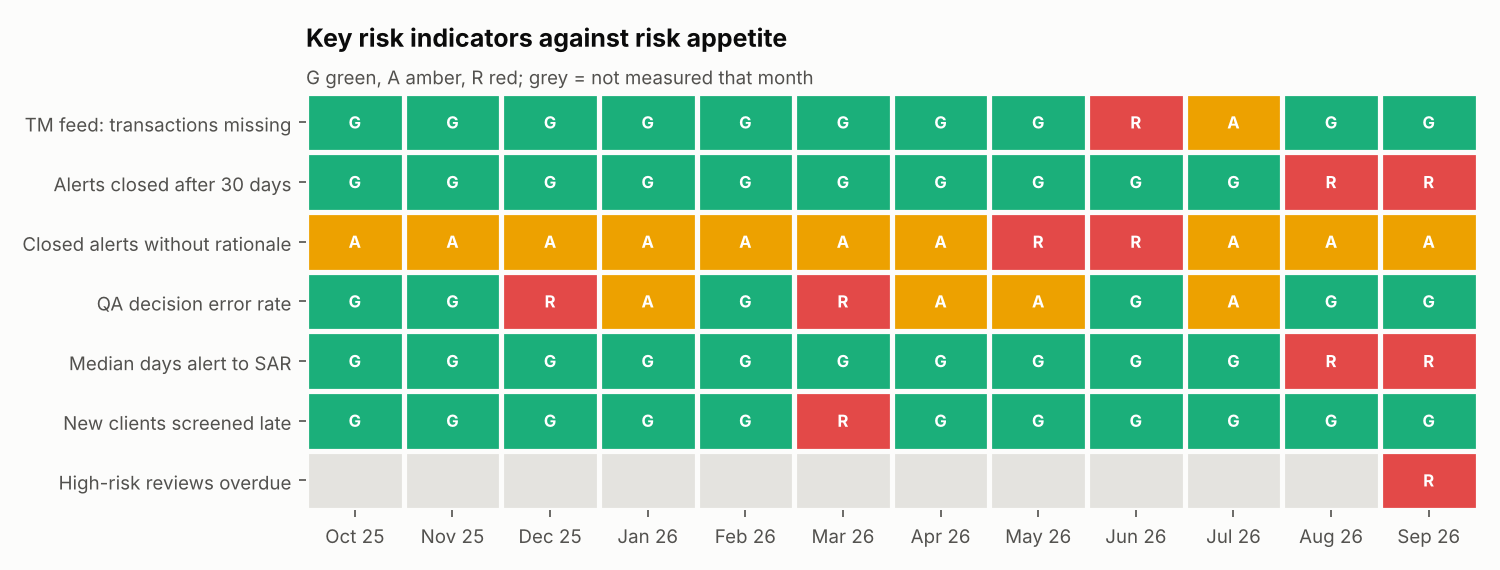

,kri,value,amber_limit,red_limit,status
77,alerts_over_sla_pct,0.3407,0.050,0.15,RED
78,qa_error_rate,0.0000,0.030,0.08,GREEN
79,missing_rationale_pct,0.0222,0.020,0.05,AMBER
80,screening_late_count,0.0000,0.000,10.00,GREEN
81,tm_feed_completeness_gap_pct,0.0000,0.001,0.01,GREEN
82,overdue_reviews_high_risk,43.0000,5.000,20.00,RED
83,median_days_alert_to_sar,53.0000,25.000,35.00,RED


In [3]:
display(Image(filename=str(reporting.plot_kri_heatmap(run.kri, Path("outputs/figures/kri_heatmap.png")))))
run.kri[run.kri["month"] == C.MONTHS[-1]][["kri", "value", "amber_limit", "red_limit", "status"]]

## Findings register

In [4]:
run.findings[["finding_id", "severity", "area", "observation", "owner", "due"]]

,finding_id,severity,area,observation,owner,due
0,F05,Critical,Sanctions screening,1 sanctions hit with match score 0.93 was closed as a false positive; reviewer judges it a true match (spelling vari...,MLRO,immediately
1,F01,High,TM data completeness,"1016 card deposits (EUR 443,188) from PSP-B never reached transaction monitoring between 2026-06-10 and 2026-07-05.",Head of TM / IT,2026-11-30
2,F03,High,Typology coverage,No rule covers T4 mule ring: 6 networks of six clients share a payout account or device; only 1 of 36 members alerte...,MLRO,2026-11-30
3,F02,High,Rule governance,R02 alert volume fell 80% from April 2026 (p = 0.000); the vendor raised the deposit count from 3 to 5 without an ap...,MLRO / TM vendor manager,2026-11-30
4,F04,High,Alert decision quality,QA found decision errors concentrated in analyst A06; a full lookback of the analyst's closures found 46 cases that ...,Head of FCC operations,2026-11-30
5,F06,Medium,Alert timeliness,"Alerts closed after more than 30 days reached 35% in 2026-08, 2026-09 (summer staffing).",Head of FCC operations,2026-12-31
6,F07,Medium,Documentation,Closed alerts without a rationale peaked at 6.0%; most come from analyst A03.,Head of FCC operations,2026-12-31
7,F08,Medium,Screening timeliness,62 new clients were screened 4 to 7 days after onboarding during a batch outage (2026-03-09 to 2026-03-13).,Head of Onboarding / IT,2026-12-31
8,F09,Medium,Periodic reviews,43 high-risk clients are past their annual review date.,Head of KYC,2026-12-31


## Excel MI pack and report

The Excel file keeps inputs (blue) apart from formulas: rates, RAG status and totals recalculate if a number is corrected. The report is one page for the Risk & Compliance Committee.

In [5]:
out = pipeline.write_outputs(run)
from openpyxl import load_workbook
wb = load_workbook(out["excel"])
print("Sheets:", wb.sheetnames)
print("Example formulas:", wb["Rules"]["G2"].value, "|", wb["QA"]["D2"].value, "|", wb["KRI dashboard"]["P2"].value[:60], "...")
print(Path("outputs/oversight_report.md").read_text()[:2500])

Sheets: ['Read me', 'KRI dashboard', 'Alert KPIs', 'Rules', 'Typology coverage', 'QA', 'Findings', 'Completeness', 'Screening', 'Reviews']
Example formulas: =E2/C2 | =C2/B2 | =IFERROR(IF(LOOKUP(2,1/(D2:O2<>""),D2:O2)<=B2,"GREEN",IF(LOO ...
# AML oversight report, October 2025 to September 2026

For senior management and the Risk & Compliance Committee. Synthetic data; the broker, clients and analysts are fictional.

## Summary

Oversight raised 9 findings: 1 critical, 4 high and 4 medium. In September 3 of 7 measured KRIs were red.

| ID | Severity | Area | Observation | Owner | Due |
|---|---|---|---|---|---|
| F05 | Critical | Sanctions screening | 1 sanctions hit with match score 0.93 was closed as a false positive; reviewer judges it a true match (spelling variant). | MLRO | immediately |
| F01 | High | TM data completeness | 1016 card deposits (EUR 443,188) from PSP-B never reached transaction monitoring between 2026-06-10 and 2026-07-05. | Head of TM / IT | 2026-11-30 |
| F03 | H